In [1]:
!unzip -q archive.zip -d /content/ravdess

In [2]:
import os

data_path = '/content/ravdess'
file_paths = []
for root, dirs, files in os.walk(data_path):
    for file in files:
        if file.endswith('.wav'):
            file_paths.append(os.path.join(root, file))

print("মোট অডিও ফাইল:", len(file_paths))
print("প্রথম ৩টা ফাইলের নাম:")
for f in file_paths[:3]:
    print(f)

মোট অডিও ফাইল: 2880
প্রথম ৩টা ফাইলের নাম:
/content/ravdess/Actor_02/03-01-05-01-02-02-02.wav
/content/ravdess/Actor_02/03-01-04-01-01-02-02.wav
/content/ravdess/Actor_02/03-01-06-02-02-02-02.wav


In [3]:
import os

data_path = '/content/ravdess'

# সব ফোল্ডার দেখি
for root, dirs, files in os.walk(data_path):
    level = root.replace(data_path, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    if level < 2:  # শুধু প্রথম ২ লেভেল দেখাই
        for d in dirs[:3]:
            print(f'{indent}  {d}/')
        if len(dirs) > 3:
            print(f'{indent}  ... আরও {len(dirs)-3}টা ফোল্ডার')

ravdess/
  Actor_02/
  Actor_15/
  Actor_06/
  ... আরও 22টা ফোল্ডার
  Actor_02/
  Actor_15/
  Actor_06/
  Actor_14/
  Actor_01/
  Actor_03/
  Actor_11/
  Actor_20/
  Actor_17/
  Actor_24/
  Actor_05/
  Actor_22/
  Actor_08/
  Actor_21/
  Actor_04/
  Actor_07/
  Actor_16/
  audio_speech_actors_01-24/
    Actor_02/
    Actor_15/
    Actor_06/
    ... আরও 21টা ফোল্ডার
    Actor_02/
    Actor_15/
    Actor_06/
    Actor_14/
    Actor_01/
    Actor_03/
    Actor_11/
    Actor_20/
    Actor_17/
    Actor_24/
    Actor_05/
    Actor_22/
    Actor_08/
    Actor_21/
    Actor_04/
    Actor_07/
    Actor_16/
    Actor_12/
    Actor_10/
    Actor_19/
    Actor_18/
    Actor_09/
    Actor_23/
    Actor_13/
  Actor_12/
  Actor_10/
  Actor_19/
  Actor_18/
  Actor_09/
  Actor_23/
  Actor_13/


In [4]:
# ডুপ্লিকেট ফোল্ডারটা মুছে ফেলি
!rm -rf /content/ravdess/audio_speech_actors_01-24

print("ডুপ্লিকেট ফোল্ডার মুছে ফেলা হয়েছে ✅")

ডুপ্লিকেট ফোল্ডার মুছে ফেলা হয়েছে ✅


In [5]:
import os

data_path = '/content/ravdess'
file_paths = []
for root, dirs, files in os.walk(data_path):
    for file in files:
        if file.endswith('.wav'):
            file_paths.append(os.path.join(root, file))

print("Total audio files:", len(file_paths))
print("\nFirst 3 files:")
for f in file_paths[:3]:
    print(f)

Total audio files: 1440

First 3 files:
/content/ravdess/Actor_02/03-01-05-01-02-02-02.wav
/content/ravdess/Actor_02/03-01-04-01-01-02-02.wav
/content/ravdess/Actor_02/03-01-06-02-02-02-02.wav


In [6]:
!pip install -q librosa soundfile

In [7]:
import librosa
import soundfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv1D, MaxPooling1D, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully.")
print("Librosa version:", librosa.__version__)

All libraries imported successfully.
Librosa version: 0.11.0


In [8]:
import os

# Collect all .wav file paths
data_path = '/content/ravdess'
file_paths = []

for root, dirs, files in os.walk(data_path):
    for file in files:
        if file.endswith('.wav'):
            file_paths.append(os.path.join(root, file))

print("Total audio files found:", len(file_paths))

# Function to extract emotion code from filename
def get_emotion_code(file_path):
    filename = os.path.basename(file_path)
    parts = filename.split('-')
    emotion_code = int(parts[2])  # 3rd part is emotion
    return emotion_code

# Extract emotion for each file
emotions = [get_emotion_code(f) for f in file_paths]

# Count how many files per emotion
from collections import Counter
emotion_counts = Counter(emotions)

# Mapping emotion code to name
emotion_map = {
    1: 'neutral',
    2: 'calm',
    3: 'happy',
    4: 'sad',
    5: 'angry',
    6: 'fearful',
    7: 'disgust',
    8: 'surprised'
}

print("\nEmotion distribution in full dataset:")
for code in sorted(emotion_counts.keys()):
    print(f"  {code} ({emotion_map[code]}): {emotion_counts[code]} files")

Total audio files found: 1440

Emotion distribution in full dataset:
  1 (neutral): 96 files
  2 (calm): 192 files
  3 (happy): 192 files
  4 (sad): 192 files
  5 (angry): 192 files
  6 (fearful): 192 files
  7 (disgust): 192 files
  8 (surprised): 192 files


In [9]:
# We keep 6 emotions: neutral, happy, sad, angry, fearful, disgust
keep_emotions = [1, 3, 4, 5, 6, 7]

filtered_paths = []
filtered_emotions = []

for path, emo in zip(file_paths, emotions):
    if emo in keep_emotions:
        filtered_paths.append(path)
        filtered_emotions.append(emo)

print("After filtering (6 classes):")
print("Total files:", len(filtered_paths))

# Count per class
from collections import Counter
filtered_counts = Counter(filtered_emotions)

emotion_map = {
    1: 'neutral',
    3: 'happy',
    4: 'sad',
    5: 'angry',
    6: 'fearful',
    7: 'disgust'
}

print("\nClass distribution:")
for code in sorted(filtered_counts.keys()):
    print(f"  {code} ({emotion_map[code]}): {filtered_counts[code]} files")

After filtering (6 classes):
Total files: 1056

Class distribution:
  1 (neutral): 96 files
  3 (happy): 192 files
  4 (sad): 192 files
  5 (angry): 192 files
  6 (fearful): 192 files
  7 (disgust): 192 files


In [10]:
import numpy as np
import librosa

def extract_mfcc(file_path, sr=22050, duration=3.0, n_mfcc=40, max_len=174):
    """
    Load audio and extract MFCC features.
    Returns array of shape (n_mfcc, max_len).
    """
    # Load audio (3 seconds, sr=22050)
    audio, sample_rate = librosa.load(file_path, sr=sr, duration=duration)

    # Extract MFCC
    mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=n_mfcc)

    # Pad or truncate to fixed length
    if mfcc.shape[1] < max_len:
        pad_width = max_len - mfcc.shape[1]
        mfcc = np.pad(mfcc, pad_width=((0, 0), (0, pad_width)), mode='constant')
    else:
        mfcc = mfcc[:, :max_len]

    return mfcc


print("Extracting MFCC features from all files...")
print("This may take 5-10 minutes. Please wait...\n")

X = []
y = []

for i, (path, emo) in enumerate(zip(filtered_paths, filtered_emotions)):
    mfcc = extract_mfcc(path)
    X.append(mfcc)
    y.append(emo)

    # Show progress every 100 files
    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{len(filtered_paths)} files...")

X = np.array(X)
y = np.array(y)

print("\n✅ Extraction complete!")
print("X shape:", X.shape)
print("y shape:", y.shape)

Extracting MFCC features from all files...
This may take 5-10 minutes. Please wait...

Processed 100/1056 files...
Processed 200/1056 files...
Processed 300/1056 files...
Processed 400/1056 files...
Processed 500/1056 files...
Processed 600/1056 files...
Processed 700/1056 files...
Processed 800/1056 files...
Processed 900/1056 files...
Processed 1000/1056 files...

✅ Extraction complete!
X shape: (1056, 40, 174)
y shape: (1056,)


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Step 1: Label Encoding (1,3,4,5,6,7 -> 0,1,2,3,4,5)
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

print("Original emotion codes:", sorted(set(y)))
print("Encoded labels:       ", sorted(set(y_encoded)))
print("Class mapping:")
for original, encoded in zip(encoder.classes_, range(len(encoder.classes_))):
    print(f"  {original} -> {encoded}")

# Step 2: One-hot encoding
y_categorical = to_categorical(y_encoded)
print("\ny_categorical shape:", y_categorical.shape)

# Step 3: Train/Test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Step 4: Add channel dimension for CNN (samples, 40, 174, 1)
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("\n✅ Data preparation complete!")
print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape: ", y_test.shape)

Original emotion codes: [np.int64(1), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
Encoded labels:        [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Class mapping:
  1 -> 0
  3 -> 1
  4 -> 2
  5 -> 3
  6 -> 4
  7 -> 5

y_categorical shape: (1056, 6)

✅ Data preparation complete!
X_train shape: (844, 40, 174, 1)
X_test shape:  (212, 40, 174, 1)
y_train shape: (844, 6)
y_test shape:  (212, 6)


In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, BatchNormalization, Dropout,
    Flatten, Dense
)

# Build CNN model
model = Sequential(name="SpeechEmotionCNN")

# Block 1
model.add(Conv1D(64, kernel_size=5, padding='same', activation='relu',
                 input_shape=(40, 174)))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.3))

# Block 2
model.add(Conv1D(128, kernel_size=5, padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.3))

# Block 3
model.add(Conv1D(256, kernel_size=5, padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.3))

# Classifier head
model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(6, activation='softmax'))  # 6 emotion classes

# Compile
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "SpeechEmotionCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 40, 64)         │        55,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 40, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 20, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 10, 256)        │       164,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 5, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 5, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 624,326 (2.38 MB)

 Trainable params: 623,430 (2.38 MB)

 Non-trainable params: 896 (3.50 KB)

In [13]:
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Early stopping to prevent overfitting
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=60,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 25s 435ms/step - accuracy: 0.2014 - loss: 2.5288 - val_accuracy: 0.2736 - val_loss: 1.8531
Epoch 2/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1967 - loss: 1.9541 - val_accuracy: 0.2170 - val_loss: 1.7690
Epoch 3/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2405 - loss: 1.7967 - val_accuracy: 0.1934 - val_loss: 1.7724
Epoch 4/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2642 - loss: 1.7356 - val_accuracy: 0.3019 - val_loss: 1.7058
Epoch 5/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2986 - loss: 1.6688 - val_accuracy: 0.3160 - val_loss: 1.6670
Epoch 6/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3021 - loss: 1.6532 - val_accuracy: 0.3915 - val_loss: 1.6017
Epoch 7/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3045 - loss: 1.6189 - val_accuracy: 0.4009 - val_loss: 1.5680
Epoch 8/60
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3412 - loss: 1.5851 - val_accuracy: 0.4292 - val_lo

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, BatchNormalization, Dropout,
    Flatten, Dense
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Clear previous session to avoid clutter
from tensorflow.keras import backend as K
K.clear_session()

# Build a smaller, regularized CNN
model = Sequential(name="SpeechEmotionCNN_v2")

model.add(Input(shape=(40, 174)))

# Block 1
model.add(Conv1D(64, kernel_size=3, padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.2))

# Block 2
model.add(Conv1D(128, kernel_size=3, padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.2))

# Block 3
model.add(Conv1D(128, kernel_size=3, padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.2))

# Classifier head (smaller)
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(6, activation='softmax'))

# Compile with lower learning rate
model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "SpeechEmotionCNN_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 40, 64)         │        33,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 40, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 20, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 10, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 640)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 191,558 (748.27 KB)

 Trainable params: 190,918 (745.77 KB)

 Non-trainable params: 640 (2.50 KB)

In [15]:
# Callbacks
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Train
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=80,
    batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/80
27/27 ━━━━━━━━━━━━━━━━━━━━ 21s 323ms/step - accuracy: 0.2121 - loss: 2.3697 - val_accuracy: 0.1934 - val_loss: 2.0801 - learning_rate: 5.0000e-04
Epoch 2/80
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2559 - loss: 1.8675 - val_accuracy: 0.2170 - val_loss: 1.8356 - learning_rate: 5.0000e-04
Epoch 3/80
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2808 - loss: 1.7629 - val_accuracy: 0.2877 - val_loss: 1.6567 - learning_rate: 5.0000e-04
Epoch 4/80
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3211 - loss: 1.6501 - val_accuracy: 0.3349 - val_loss: 1.6026 - learning_rate: 5.0000e-04
Epoch 5/80
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3803 - loss: 1.5573 - val_accuracy: 0.3538 - val_loss: 1.5763 - learning_rate: 5.0000e-04
Epoch 6/80
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3780 - loss: 1.5267 - val_accuracy: 0.4104 - val_loss: 1.5338 - learning_rate: 5.0000e-04
Epoch 7/80
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4111 - lo

In [16]:
import numpy as np
import librosa

def extract_mfcc_augmented(file_path, sr=22050, duration=3.0, n_mfcc=40, max_len=174):
    """
    Extract MFCC from original audio + 2 augmented versions.
    Returns 3 arrays, each of shape (n_mfcc, max_len).
    """
    audio, sample_rate = librosa.load(file_path, sr=sr, duration=duration)

    # Ensure consistent length
    target_length = int(sr * duration)
    if len(audio) < target_length:
        audio = np.pad(audio, (0, target_length - len(audio)), mode='constant')
    else:
        audio = audio[:target_length]

    def to_mfcc(a):
        m = librosa.feature.mfcc(y=a, sr=sr, n_mfcc=n_mfcc)
        if m.shape[1] < max_len:
            m = np.pad(m, ((0, 0), (0, max_len - m.shape[1])), mode='constant')
        else:
            m = m[:, :max_len]
        return m

    # Version 1: Original
    mfcc_original = to_mfcc(audio)

    # Version 2: Add slight noise
    noise = np.random.randn(len(audio)) * 0.005
    audio_noise = audio + noise
    mfcc_noise = to_mfcc(audio_noise)

    # Version 3: Time shift (roll by 10% of length)
    shift = int(len(audio) * 0.1)
    audio_shift = np.roll(audio, shift)
    mfcc_shift = to_mfcc(audio_shift)

    return mfcc_original, mfcc_noise, mfcc_shift


print("Extracting MFCC with augmentation (3x data)...")
print("This will take 10-15 minutes. Please wait...\n")

X_aug = []
y_aug = []

for i, (path, emo) in enumerate(zip(filtered_paths, filtered_emotions)):
    m1, m2, m3 = extract_mfcc_augmented(path)
    X_aug.extend([m1, m2, m3])
    y_aug.extend([emo, emo, emo])

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{len(filtered_paths)} files -> {len(X_aug)} samples so far")

X_aug = np.array(X_aug)
y_aug = np.array(y_aug)

print("\n✅ Augmentation complete!")
print("X shape:", X_aug.shape)
print("y shape:", y_aug.shape)

Extracting MFCC with augmentation (3x data)...
This will take 10-15 minutes. Please wait...

Processed 100/1056 files -> 300 samples so far
Processed 200/1056 files -> 600 samples so far
Processed 300/1056 files -> 900 samples so far
Processed 400/1056 files -> 1200 samples so far
Processed 500/1056 files -> 1500 samples so far
Processed 600/1056 files -> 1800 samples so far
Processed 700/1056 files -> 2100 samples so far
Processed 800/1056 files -> 2400 samples so far
Processed 900/1056 files -> 2700 samples so far
Processed 1000/1056 files -> 3000 samples so far

✅ Augmentation complete!
X shape: (3168, 40, 174)
y shape: (3168,)


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Encode labels
encoder = LabelEncoder()
y_aug_encoded = encoder.fit_transform(y_aug)
y_aug_categorical = to_categorical(y_aug_encoded)

print("Encoded classes:", encoder.classes_)
print("y_categorical shape:", y_aug_categorical.shape)

# Train/Test split (80/20, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X_aug, y_aug_categorical,
    test_size=0.2,
    random_state=42,
    stratify=y_aug_encoded
)

# Add channel dimension for CNN
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("\nData split complete!")
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

Encoded classes: [1 3 4 5 6 7]
y_categorical shape: (3168, 6)

Data split complete!
X_train: (2534, 40, 174, 1)
X_test:  (634, 40, 174, 1)
y_train: (2534, 6)
y_test:  (634, 6)


In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, BatchNormalization, Dropout,
    Flatten, Dense
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import backend as K

K.clear_session()

model = Sequential(name="SpeechEmotionCNN_v3")
model.add(Input(shape=(40, 174)))

# Block 1
model.add(Conv1D(64, kernel_size=3, padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.2))

# Block 2
model.add(Conv1D(128, kernel_size=3, padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.2))

# Block 3
model.add(Conv1D(128, kernel_size=3, padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.3))

# Classifier head
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(6, activation='softmax'))

model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "SpeechEmotionCNN_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 40, 64)         │        33,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 40, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 20, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 10, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 5, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 640)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 191,558 (748.27 KB)

 Trainable params: 190,918 (745.77 KB)

 Non-trainable params: 640 (2.50 KB)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=80,
    batch_size=32,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/80
80/80 ━━━━━━━━━━━━━━━━━━━━ 17s 122ms/step - accuracy: 0.2052 - loss: 2.3884 - val_accuracy: 0.2129 - val_loss: 1.7571 - learning_rate: 5.0000e-04
Epoch 2/80
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2257 - loss: 1.7820 - val_accuracy: 0.2539 - val_loss: 1.7456 - learning_rate: 5.0000e-04
Epoch 3/80
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2660 - loss: 1.7046 - val_accuracy: 0.2823 - val_loss: 1.6767 - learning_rate: 5.0000e-04
Epoch 4/80
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2912 - loss: 1.6433 - val_accuracy: 0.4164 - val_loss: 1.5633 - learning_rate: 5.0000e-04
Epoch 5/80
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3465 - loss: 1.5830 - val_accuracy: 0.4180 - val_loss: 1.4612 - learning_rate: 5.0000e-04
Epoch 6/80
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3694 - loss: 1.5319 - val_accuracy: 0.4227 - val_loss: 1.4144 - learning_rate: 5.0000e-04
Epoch 7/80
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3871 - lo

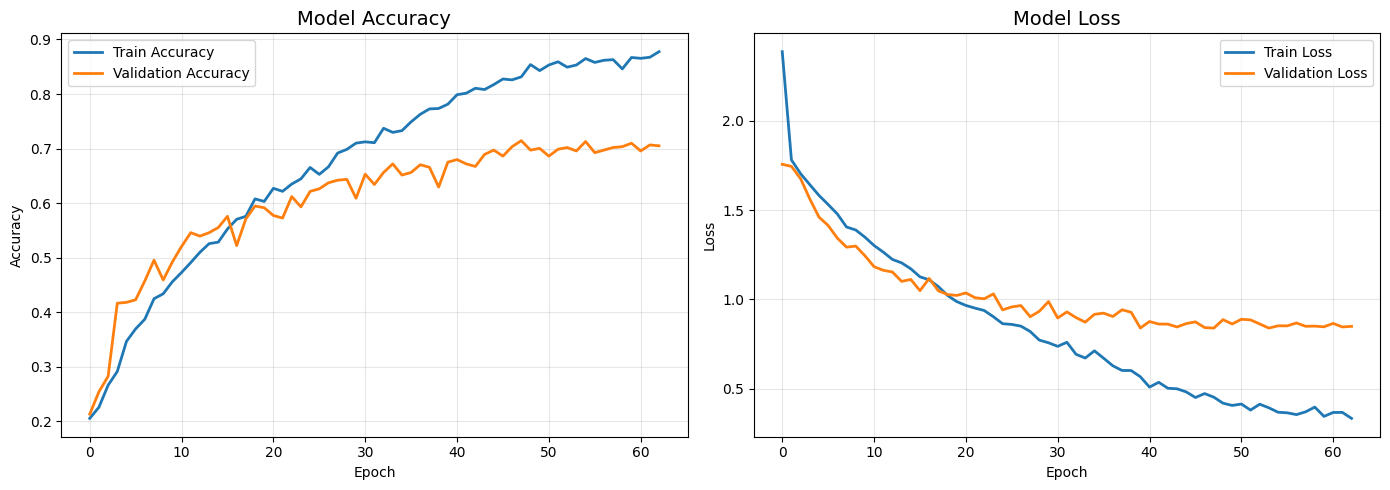

✅ Training history saved as 'training_history.png'

FINAL EVALUATION ON TEST SET
Test Loss:     0.8393
Test Accuracy: 71.45%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     neutral     0.6471    0.5690    0.6055        58
       happy     0.6504    0.6957    0.6723       115
         sad     0.6250    0.5652    0.5936       115
       angry     0.7967    0.8522    0.8235       115
     fearful     0.7670    0.6810    0.7215       116
     disgust     0.7538    0.8522    0.8000       115

    accuracy                         0.7145       634
   macro avg     0.7067    0.7025    0.7027       634
weighted avg     0.7121    0.7145    0.7115       634



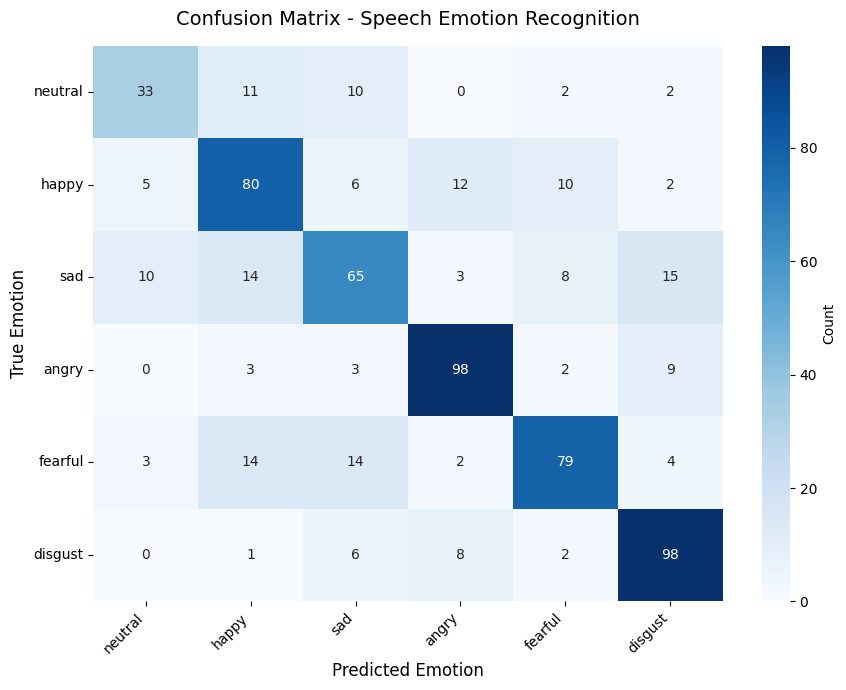

✅ Confusion matrix saved as 'confusion_matrix.png'

✅ Model saved as 'emotion_recognition_model.h5'
✅ Label encoder saved as 'label_encoder.pkl'


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# ============================================
# 1. Training History Graph
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[0].set_title('Model Accuracy', fontsize=14)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[1].set_title('Model Loss', fontsize=14)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Training history saved as 'training_history.png'")

# ============================================
# 2. Final Evaluation
# ============================================
print("\n" + "="*50)
print("FINAL EVALUATION ON TEST SET")
print("="*50)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc*100:.2f}%")

# ============================================
# 3. Classification Report
# ============================================
y_pred = model.predict(X_test, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

emotion_labels = ['neutral', 'happy', 'sad', 'angry', 'fearful', 'disgust']

print("\n" + "="*50)
print("CLASSIFICATION REPORT")
print("="*50)
print(classification_report(y_true_classes, y_pred_classes,
                            target_names=emotion_labels, digits=4))

# ============================================
# 4. Confusion Matrix
# ============================================
cm = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=emotion_labels,
            yticklabels=emotion_labels,
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Speech Emotion Recognition', fontsize=14, pad=15)
plt.xlabel('Predicted Emotion', fontsize=12)
plt.ylabel('True Emotion', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Confusion matrix saved as 'confusion_matrix.png'")

# ============================================
# 5. Save Model
# ============================================
model.save('emotion_recognition_model.h5')
print("\n✅ Model saved as 'emotion_recognition_model.h5'")

# Save label encoder classes too (needed later for prediction)
import pickle
with open('label_encoder.pkl', 'wb') as f:
    pickle.dump(encoder, f)
print("✅ Label encoder saved as 'label_encoder.pkl'")

In [21]:
import numpy as np
import librosa
import pickle
import os
import random

from tensorflow.keras.models import load_model

# ============================================
# Load trained model and encoder
# ============================================
model = load_model('emotion_recognition_model.h5')

with open('label_encoder.pkl', 'rb') as f:
    encoder = pickle.load(f)

emotion_map = {
    1: 'neutral',
    3: 'happy',
    4: 'sad',
    5: 'angry',
    6: 'fearful',
    7: 'disgust'
}

# ============================================
# Prediction function
# ============================================
def predict_emotion(file_path, sr=22050, duration=3.0, n_mfcc=40, max_len=174):
    """
    Predict emotion from a single audio file.
    Returns: (emotion_name, confidence, top3_predictions)
    """
    # Load audio
    audio, sample_rate = librosa.load(file_path, sr=sr, duration=duration)

    # Pad/truncate to 3 seconds
    target_length = int(sr * duration)
    if len(audio) < target_length:
        audio = np.pad(audio, (0, target_length - len(audio)), mode='constant')
    else:
        audio = audio[:target_length]

    # Extract MFCC
    mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=n_mfcc)

    # Pad/truncate time axis to 174
    if mfcc.shape[1] < max_len:
        mfcc = np.pad(mfcc, ((0, 0), (0, max_len - mfcc.shape[1])), mode='constant')
    else:
        mfcc = mfcc[:, :max_len]

    # Add batch + channel dimension
    mfcc = mfcc[np.newaxis, ..., np.newaxis]  # (1, 40, 174, 1)

    # Predict
    pred = model.predict(mfcc, verbose=0)
    pred_class = np.argmax(pred[0])
    confidence = pred[0][pred_class] * 100

    original_code = encoder.classes_[pred_class]
    emotion_name = emotion_map[original_code]

    # Top 3
    top3_idx = np.argsort(pred[0])[::-1][:3]
    top3 = [(emotion_map[encoder.classes_[i]], pred[0][i] * 100) for i in top3_idx]

    return emotion_name, confidence, top3


# ============================================
# Test on 5 random files from the dataset
# ============================================
print("=" * 60)
print("SINGLE AUDIO PREDICTION DEMO")
print("=" * 60)

random.seed(42)
sample_paths = random.sample(filtered_paths, 5)

correct = 0
for path in sample_paths:
    true_emotion_code = int(os.path.basename(path).split('-')[2])
    true_emotion = emotion_map[true_emotion_code]

    predicted, confidence, top3 = predict_emotion(path)

    status = "✅" if predicted == true_emotion else "❌"
    if predicted == true_emotion:
        correct += 1

    print(f"\n{status} File: {os.path.basename(path)}")
    print(f"   True:      {true_emotion}")
    print(f"   Predicted: {predicted} ({confidence:.2f}%)")
    print(f"   Top 3:     {', '.join([f'{e} ({c:.1f}%)' for e, c in top3])}")

print("\n" + "=" * 60)
print(f"Result: {correct}/5 correct predictions")
print("=" * 60)

SINGLE AUDIO PREDICTION DEMO

✅ File: 03-01-05-01-02-01-03.wav
   True:      angry
   Predicted: angry (99.49%)
   Top 3:     angry (99.5%), happy (0.3%), disgust (0.2%)

✅ File: 03-01-03-02-02-02-15.wav
   True:      happy
   Predicted: happy (85.41%)
   Top 3:     happy (85.4%), angry (10.7%), fearful (1.1%)

✅ File: 03-01-05-01-01-01-08.wav
   True:      angry
   Predicted: angry (99.93%)
   Top 3:     angry (99.9%), happy (0.1%), fearful (0.0%)

✅ File: 03-01-04-02-01-01-22.wav
   True:      sad
   Predicted: sad (99.37%)
   Top 3:     sad (99.4%), neutral (0.4%), fearful (0.2%)

❌ File: 03-01-03-01-02-01-05.wav
   True:      happy
   Predicted: sad (58.47%)
   Top 3:     sad (58.5%), happy (12.1%), neutral (12.0%)

Result: 4/5 correct predictions


In [22]:
import os
import json
import pickle
import numpy as np

# ============================================
# 1. Save model in BOTH formats
# ============================================
model.save('emotion_recognition_model.keras')  # New Keras format (recommended)
model.save('emotion_recognition_model.h5')     # Legacy format (widely supported)

print("✅ Model saved in two formats:")
print("   - emotion_recognition_model.keras")
print("   - emotion_recognition_model.h5")

# ============================================
# 2. Save training history (for report/README)
# ============================================
history_dict = {
    'accuracy': [float(x) for x in history.history['accuracy']],
    'val_accuracy': [float(x) for x in history.history['val_accuracy']],
    'loss': [float(x) for x in history.history['loss']],
    'val_loss': [float(x) for x in history.history['val_loss']],
    'best_val_accuracy': float(max(history.history['val_accuracy'])),
    'best_epoch': int(np.argmax(history.history['val_accuracy']) + 1),
    'total_epochs': len(history.history['accuracy'])
}

with open('training_history.json', 'w') as f:
    json.dump(history_dict, f, indent=2)

print("\n✅ Training history saved as 'training_history.json'")
print(f"   Best val_accuracy: {history_dict['best_val_accuracy']*100:.2f}% (epoch {history_dict['best_epoch']})")

# ============================================
# 3. Save model architecture as text
# ============================================
with open('model_architecture.txt', 'w') as f:
    model.summary(print_fn=lambda x: f.write(x + '\n'))

print("✅ Model architecture saved as 'model_architecture.txt'")

# ============================================
# 4. Save class mapping
# ============================================
class_mapping = {
    'index_to_emotion': {
        0: 'neutral', 1: 'happy', 2: 'sad',
        3: 'angry', 4: 'fearful', 5: 'disgust'
    },
    'ravdess_original_codes': {
        'neutral': 1, 'happy': 3, 'sad': 4,
        'angry': 5, 'fearful': 6, 'disgust': 7
    }
}

with open('class_mapping.json', 'w') as f:
    json.dump(class_mapping, f, indent=2)

print("✅ Class mapping saved as 'class_mapping.json'")

# ============================================
# 5. Save feature extraction config
# ============================================
config = {
    'sample_rate': 22050,
    'duration_seconds': 3.0,
    'n_mfcc': 40,
    'max_time_steps': 174,
    'n_classes': 6,
    'emotions': ['neutral', 'happy', 'sad', 'angry', 'fearful', 'disgust'],
    'dataset': 'RAVDESS',
    'original_samples': 1056,
    'augmented_samples': 3168,
    'augmentation': ['original', 'add_noise', 'time_shift'],
    'train_test_split': '80/20',
    'random_seed': 42,
    'test_accuracy': 0.7145
}

with open('config.json', 'w') as f:
    json.dump(config, f, indent=2)

print("✅ Config saved as 'config.json'")

# ============================================
# 6. Final summary
# ============================================
print("\n" + "=" * 60)
print("📦 ALL PROJECT FILES READY FOR GITHUB")
print("=" * 60)

files_to_upload = [
    'emotion_recognition_model.keras',
    'emotion_recognition_model.h5',
    'label_encoder.pkl',
    'training_history.json',
    'training_history.png',
    'confusion_matrix.png',
    'model_architecture.txt',
    'class_mapping.json',
    'config.json'
]

print("\nFiles in /content/:")
for f in files_to_upload:
    if os.path.exists(f):
        size = os.path.getsize(f) / 1024
        print(f"  ✅ {f:45s} ({size:8.1f} KB)")
    else:
        print(f"  ❌ {f:45s} (MISSING!)")

total = sum(1 for f in files_to_upload if os.path.exists(f))
print(f"\n✅ Total files ready: {total}/{len(files_to_upload)}")

✅ Model saved in two formats:
   - emotion_recognition_model.keras
   - emotion_recognition_model.h5

✅ Training history saved as 'training_history.json'
   Best val_accuracy: 71.45% (epoch 48)


✅ Model architecture saved as 'model_architecture.txt'
✅ Class mapping saved as 'class_mapping.json'
✅ Config saved as 'config.json'

📦 ALL PROJECT FILES READY FOR GITHUB

Files in /content/:
  ✅ emotion_recognition_model.keras               (   806.8 KB)
  ✅ emotion_recognition_model.h5                  (   812.0 KB)
  ✅ label_encoder.pkl                             (     0.3 KB)
  ✅ training_history.json                         (     6.1 KB)
  ✅ training_history.png                          (   111.2 KB)
  ✅ confusion_matrix.png                          (    73.9 KB)
  ✅ model_architecture.txt                        (     5.9 KB)
  ✅ class_mapping.json                            (     0.3 KB)
  ✅ config.json                                   (     0.4 KB)

✅ Total files ready: 9/9


In [23]:
# Free up RAM before starting
import gc
del X_aug, y_aug, X, y
gc.collect()
print("RAM freed. Ready to extract advanced features.")

RAM freed. Ready to extract advanced features.


In [24]:
import numpy as np
import librosa

def extract_advanced_features(file_path, sr=22050, duration=3.0, max_len=174):
    """
    Extract combined audio features:
    - MFCC (40) + delta (40) + delta-delta (40) = 120
    - Chroma (12)
    - Mel-spectrogram (128)
    - ZCR (1)
    - Spectral centroid (1)
    - RMS energy (1)
    Total: 263 features per time-step
    """
    audio, sample_rate = librosa.load(file_path, sr=sr, duration=duration)

    target_length = int(sr * duration)
    if len(audio) < target_length:
        audio = np.pad(audio, (0, target_length - len(audio)), mode='constant')
    else:
        audio = audio[:target_length]

    # 1. MFCC + deltas
    mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
    mfcc_delta = librosa.feature.delta(mfcc)
    mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

    # 2. Chroma
    chroma = librosa.feature.chroma_stft(y=audio, sr=sample_rate, n_chroma=12)

    # 3. Mel-spectrogram
    mel = librosa.feature.melspectrogram(y=audio, sr=sample_rate, n_mels=128)
    mel_db = librosa.power_to_db(mel, ref=np.max)

    # 4. ZCR
    zcr = librosa.feature.zero_crossing_rate(audio)

    # 5. Spectral centroid
    spec_cent = librosa.feature.spectral_centroid(y=audio, sr=sample_rate)

    # 6. RMS energy
    rms = librosa.feature.rms(y=audio)

    # Stack
    features = np.vstack([mfcc, mfcc_delta, mfcc_delta2,
                          chroma, mel_db, zcr, spec_cent, rms])

    # Pad/truncate
    if features.shape[1] < max_len:
        features = np.pad(features, ((0, 0), (0, max_len - features.shape[1])),
                          mode='constant')
    else:
        features = features[:, :max_len]

    return features


# Test on one file
test_features = extract_advanced_features(filtered_paths[0])
print("Feature shape for one file:", test_features.shape)
print("Expected: (263, 174)")

Feature shape for one file: (263, 174)
Expected: (263, 174)


In [25]:
import numpy as np

def extract_with_augmentation(file_path):
    """Extract 3 augmented versions of advanced features."""
    sr = 22050
    duration = 3.0
    max_len = 174

    audio, sample_rate = librosa.load(file_path, sr=sr, duration=duration)
    target_length = int(sr * duration)
    if len(audio) < target_length:
        audio = np.pad(audio, (0, target_length - len(audio)), mode='constant')
    else:
        audio = audio[:target_length]

    def audio_to_features(a):
        mfcc = librosa.feature.mfcc(y=a, sr=sr, n_mfcc=40)
        mfcc_delta = librosa.feature.delta(mfcc)
        mfcc_delta2 = librosa.feature.delta(mfcc, order=2)
        chroma = librosa.feature.chroma_stft(y=a, sr=sr, n_chroma=12)
        mel = librosa.feature.melspectrogram(y=a, sr=sr, n_mels=128)
        mel_db = librosa.power_to_db(mel, ref=np.max)
        zcr = librosa.feature.zero_crossing_rate(a)
        spec_cent = librosa.feature.spectral_centroid(y=a, sr=sr)
        rms = librosa.feature.rms(y=a)

        feats = np.vstack([mfcc, mfcc_delta, mfcc_delta2,
                           chroma, mel_db, zcr, spec_cent, rms])
        if feats.shape[1] < max_len:
            feats = np.pad(feats, ((0, 0), (0, max_len - feats.shape[1])), mode='constant')
        else:
            feats = feats[:, :max_len]
        return feats

    f1 = audio_to_features(audio)

    noise = np.random.randn(len(audio)) * 0.005
    f2 = audio_to_features(audio + noise)

    shift = int(len(audio) * 0.1)
    f3 = audio_to_features(np.roll(audio, shift))

    return f1, f2, f3


print("Extracting advanced features (263 dims) with augmentation...")
print("This will take 15-20 minutes. Please wait...\n")

X_adv = []
y_adv = []

for i, (path, emo) in enumerate(zip(filtered_paths, filtered_emotions)):
    f1, f2, f3 = extract_with_augmentation(path)
    X_adv.extend([f1, f2, f3])
    y_adv.extend([emo, emo, emo])

    if (i + 1) % 100 == 0:
        print(f"Processed {i+1}/{len(filtered_paths)} files -> {len(X_adv)} samples")

X_adv = np.array(X_adv)
y_adv = np.array(y_adv)

print("\n✅ Advanced feature extraction complete!")
print("X_adv shape:", X_adv.shape)
print("y_adv shape:", y_adv.shape)

Extracting advanced features (263 dims) with augmentation...
This will take 15-20 minutes. Please wait...

Processed 100/1056 files -> 300 samples
Processed 200/1056 files -> 600 samples
Processed 300/1056 files -> 900 samples
Processed 400/1056 files -> 1200 samples
Processed 500/1056 files -> 1500 samples
Processed 600/1056 files -> 1800 samples
Processed 700/1056 files -> 2100 samples
Processed 800/1056 files -> 2400 samples
Processed 900/1056 files -> 2700 samples
Processed 1000/1056 files -> 3000 samples

✅ Advanced feature extraction complete!
X_adv shape: (3168, 263, 174)
y_adv shape: (3168,)


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
import numpy as np

# Encode labels
encoder_adv = LabelEncoder()
y_adv_encoded = encoder_adv.fit_transform(y_adv)
y_adv_categorical = to_categorical(y_adv_encoded)

print("Classes:", encoder_adv.classes_)
print("y_categorical shape:", y_adv_categorical.shape)

# Train/Test split (stratified)
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_adv, y_adv_categorical,
    test_size=0.2,
    random_state=42,
    stratify=y_adv_encoded
)

# Add channel dimension
X_train_a = X_train_a[..., np.newaxis]
X_test_a = X_test_a[..., np.newaxis]

print("\nData split ready!")
print("X_train_a:", X_train_a.shape)
print("X_test_a: ", X_test_a.shape)
print("y_train_a:", y_train_a.shape)
print("y_test_a: ", y_test_a.shape)

Classes: [1 3 4 5 6 7]
y_categorical shape: (3168, 6)

Data split ready!
X_train_a: (2534, 263, 174, 1)
X_test_a:  (634, 263, 174, 1)
y_train_a: (2534, 6)
y_test_a:  (634, 6)


In [28]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, BatchNormalization, Dropout,
    Bidirectional, LSTM, Dense, Multiply, Activation, Lambda
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import backend as K

K.clear_session()

# ============================================
# Build CNN + BiLSTM + Attention model (FIXED)
# ============================================
inputs = Input(shape=(263, 174), name='audio_features')

# --- CNN Block ---
x = Conv1D(64, kernel_size=5, padding='same', activation='relu')(inputs)
x = BatchNormalization()(x)
x = MaxPooling1D(pool_size=2)(x)  # 174 -> 87
x = Dropout(0.2)(x)

x = Conv1D(128, kernel_size=5, padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling1D(pool_size=2)(x)  # 87 -> 43
x = Dropout(0.2)(x)

x = Conv1D(128, kernel_size=3, padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling1D(pool_size=2)(x)  # 43 -> 21
x = Dropout(0.3)(x)

# --- Bidirectional LSTM ---
x = Bidirectional(LSTM(128, return_sequences=True))(x)  # (batch, 21, 256)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

# --- Attention Mechanism (FIXED) ---
# Compute attention score per time-step: (batch, 21, 256) -> (batch, 21, 1)
attention_scores = Dense(1, activation='tanh')(x)

# Softmax over TIME axis (axis=1), not the feature axis
attention_weights = Activation('softmax')(attention_scores)  # (batch, 21, 1)

# Multiply: broadcasting (batch, 21, 256) * (batch, 21, 1) -> (batch, 21, 256)
weighted = Multiply()([x, attention_weights])

# Sum over time axis -> context vector (batch, 256)
context = Lambda(lambda t: K.sum(t, axis=1))(weighted)

# --- Classifier Head ---
x = Dense(128, activation='relu')(context)
x = Dropout(0.4)(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(6, activation='softmax', name='emotion_output')(x)

model_adv = Model(inputs=inputs, outputs=outputs, name='CNN_BiLSTM_Attention')

model_adv.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_adv.summary()

Model: "CNN_BiLSTM_Attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ audio_features      │ (None, 263, 174)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 263, 64)   │     55,744 │ audio_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 263, 64)   │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 131, 64)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 131, 64)   │          0 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 131, 128)  │     41,088 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 131, 128)  │        512 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 65, 128)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 65, 128)   │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 65, 128)   │     49,280 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 65, 128)   │        512 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 32, 128)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32, 128)   │          0 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 32, 256)   │    263,168 │ dropout_2[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 256)   │      1,024 │ bidirectional[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32, 256)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32, 1)     │        257 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 1)     │          0 │ dense[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 32, 256)   │          0 │ dropout_3[0][0],  │
│                     │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 453,383 (1.73 MB)

 Trainable params: 452,231 (1.73 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [29]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Callbacks
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=6,
    min_lr=1e-6,
    verbose=1
)

# Save best model during training
checkpoint = ModelCheckpoint(
    'best_model_adv.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Train
history_adv = model_adv.fit(
    X_train_a, y_train_a,
    validation_data=(X_test_a, y_test_a),
    epochs=80,
    batch_size=32,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

Epoch 1/80


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 32, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.1729 - loss: 12.3683
Epoch 1: val_accuracy improved from None to 0.18297, saving model to best_model_adv.keras

Epoch 1: finished saving model to best_model_adv.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.1721 - loss: 8.9203 - val_accuracy: 0.1830 - val_loss: 2.1593 - learning_rate: 5.0000e-04
Epoch 2/80
78/80 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1708 - loss: 4.4125
Epoch 2: val_accuracy improved from 0.18297 to 0.24132, saving model to best_model_adv.keras

Epoch 2: finished saving model to best_model_adv.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.1768 - loss: 3.9962 - val_accuracy: 0.2413 - val_loss: 1.8570 - learning_rate: 5.0000e-04
Epoch 3/80
79/80 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1767 - loss: 3.1439
Epoch 3: val_accuracy did not improve from 0.24132
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.1823 - loss: 3.0313 - val_accuracy: 0.2035 - val_loss: 1.8500 - le

In [30]:
import numpy as np
from sklearn.preprocessing import StandardScaler
import gc

# ============================================
# Reshape features from (n, 263, 174) to (n*174, 263) for scaling
# ============================================
print("Original shape:", X_adv.shape)

n_samples, n_features, n_timesteps = X_adv.shape

# Transpose to (n, 174, 263) then reshape to (n*174, 263)
X_reshaped = X_adv.transpose(0, 2, 1).reshape(-1, n_features)
print("Reshaped for scaling:", X_reshaped.shape)

# Apply StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_reshaped)

# Reshape back to (n, 174, 263) then transpose to (n, 263, 174)
X_scaled = X_scaled.reshape(n_samples, n_timesteps, n_features)
X_scaled = X_scaled.transpose(0, 2, 1)

print("Scaled shape:", X_scaled.shape)
print("Feature mean (should be ~0):", X_scaled.mean())
print("Feature std (should be ~1):", X_scaled.std())

# Free memory
del X_reshaped, X_adv
gc.collect()

print("\n✅ Scaling complete!")

Original shape: (3168, 263, 174)
Reshaped for scaling: (551232, 263)
Scaled shape: (3168, 263, 174)
Feature mean (should be ~0): -5.694082830224383e-16
Feature std (should be ~1): 0.9999999999999615

✅ Scaling complete!


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
import numpy as np

# Encode labels
encoder_v2 = LabelEncoder()
y_v2_encoded = encoder_v2.fit_transform(y_adv)
y_v2_categorical = to_categorical(y_v2_encoded)

print("Classes:", encoder_v2.classes_)
print("y_categorical shape:", y_v2_categorical.shape)

# Train/Test split
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_scaled, y_v2_categorical,
    test_size=0.2,
    random_state=42,
    stratify=y_v2_encoded
)

# Add channel dimension for CNN
X_train_s = X_train_s[..., np.newaxis]
X_test_s = X_test_s[..., np.newaxis]

print("\nData split ready!")
print("X_train_s:", X_train_s.shape)
print("X_test_s: ", X_test_s.shape)
print("y_train_s:", y_train_s.shape)
print("y_test_s: ", y_test_s.shape)

Classes: [1 3 4 5 6 7]
y_categorical shape: (3168, 6)

Data split ready!
X_train_s: (2534, 263, 174, 1)
X_test_s:  (634, 263, 174, 1)
y_train_s: (2534, 6)
y_test_s:  (634, 6)


In [32]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, BatchNormalization, Dropout,
    Bidirectional, LSTM, Dense, GlobalAveragePooling1D, GlobalMaxPooling1D,
    Concatenate
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import backend as K

K.clear_session()

# ============================================
# Simpler CNN + BiLSTM model (no attention bug)
# ============================================
inputs = Input(shape=(263, 174), name='audio_features')

# --- CNN Block: local pattern extraction ---
x = Conv1D(64, kernel_size=5, padding='same', activation='relu')(inputs)
x = BatchNormalization()(x)
x = MaxPooling1D(pool_size=2)(x)  # 174 -> 87
x = Dropout(0.2)(x)

x = Conv1D(128, kernel_size=5, padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling1D(pool_size=2)(x)  # 87 -> 43
x = Dropout(0.2)(x)

x = Conv1D(128, kernel_size=3, padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = MaxPooling1D(pool_size=2)(x)  # 43 -> 21
x = Dropout(0.3)(x)

# --- BiLSTM Block: temporal sequence ---
x = Bidirectional(LSTM(96, return_sequences=True))(x)   # (batch, 21, 192)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

# --- Dual Pooling: keep both avg and max info ---
avg_pool = GlobalAveragePooling1D()(x)   # (batch, 192)
max_pool = GlobalMaxPooling1D()(x)       # (batch, 192)
x = Concatenate()([avg_pool, max_pool])  # (batch, 384)

# --- Classifier Head ---
x = Dense(128, activation='relu')(x)
x = Dropout(0.4)(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(6, activation='softmax', name='emotion_output')(x)

model_v3 = Model(inputs=inputs, outputs=outputs, name='CNN_BiLSTM_v3')

model_v3.compile(
    optimizer=Adam(learning_rate=0.0003),  # lower LR for stability
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_v3.summary()

Model: "CNN_BiLSTM_v3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ audio_features      │ (None, 263, 174)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 263, 64)   │     55,744 │ audio_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 263, 64)   │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 131, 64)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 131, 64)   │          0 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 131, 128)  │     41,088 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 131, 128)  │        512 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 65, 128)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 65, 128)   │          0 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 65, 128)   │     49,280 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 65, 128)   │        512 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 32, 128)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32, 128)   │          0 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 32, 192)   │    172,800 │ dropout_2[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 192)   │        768 │ bidirectional[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32, 192)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 192)       │          0 │ dropout_3[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 192)       │          0 │ dropout_3[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 384)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli

 Total params: 378,886 (1.45 MB)

 Trainable params: 377,862 (1.44 MB)

 Non-trainable params: 1,024 (4.00 KB)

In [33]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=6,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'best_model_v3.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

history_v3 = model_v3.fit(
    X_train_s, y_train_s,
    validation_data=(X_test_s, y_test_s),
    epochs=80,
    batch_size=32,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

Epoch 1/80
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1849 - loss: 2.2990
Epoch 1: val_accuracy improved from None to 0.22555, saving model to best_model_v3.keras

Epoch 1: finished saving model to best_model_v3.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.1922 - loss: 2.0084 - val_accuracy: 0.2256 - val_loss: 1.7632 - learning_rate: 3.0000e-04
Epoch 2/80
77/80 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2043 - loss: 1.7768
Epoch 2: val_accuracy did not improve from 0.22555
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.2174 - loss: 1.7652 - val_accuracy: 0.2240 - val_loss: 1.7379 - learning_rate: 3.0000e-04
Epoch 3/80
78/80 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2243 - loss: 1.7368
Epoch 3: val_accuracy improved from 0.22555 to 0.28707, saving model to best_model_v3.keras

Epoch 3: finished saving model to best_model_v3.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.2234 - loss: 1.7340 - val_accuracy: 0.2871 - val_loss: 1.7242

In [34]:
import os

# Check which model file we have
print("Files in /content/:")
for f in os.listdir('.'):
    if f.endswith(('.h5', '.keras')):
        size_mb = os.path.getsize(f) / 1024 / 1024
        print(f"  {f:45s} ({size_mb:.2f} MB)")

Files in /content/:
  best_model_v3.keras                           (4.44 MB)
  emotion_recognition_model.keras               (0.79 MB)
  emotion_recognition_model.h5                  (0.79 MB)
  best_model_adv.keras                          (5.30 MB)


In [1]:
import os

print("=" * 50)
print("COLAB STATE AFTER RESTART")
print("=" * 50)

# Check /content/ files
print("\n📁 Files in /content/:")
for f in os.listdir('/content'):
    if not f.startswith('.'):
        path = f'/content/{f}'
        if os.path.isfile(path):
            size_mb = os.path.getsize(path) / 1024 / 1024
            print(f"  {f:45s} ({size_mb:.2f} MB)")
        else:
            print(f"  {f}/ (folder)")

# Check if Drive is mounted
print("\n💾 Google Drive status:")
if os.path.exists('/content/drive/MyDrive'):
    print("  ✅ Drive is MOUNTED")
else:
    print("  ❌ Drive NOT mounted")

# Check ravdess folder
print("\n🎵 RAVDESS dataset:")
if os.path.exists('/content/ravdess'):
    wav_count = 0
    for root, dirs, files in os.walk('/content/ravdess'):
        wav_count += sum(1 for f in files if f.endswith('.wav'))
    print(f"  ✅ Found {wav_count} .wav files")
else:
    print("  ❌ RAVDESS folder NOT found")

# Check GPU
import tensorflow as tf
print("\n🖥️ GPU status:")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"  ✅ GPU available: {gpus[0].name}")
else:
    print("  ❌ No GPU")

COLAB STATE AFTER RESTART

📁 Files in /content/:
  class_mapping.json                            (0.00 MB)
  archive.zip                                   (429.25 MB)
  best_model_v3.keras                           (4.44 MB)
  emotion_recognition_model.keras               (0.79 MB)
  training_history.png                          (0.11 MB)
  label_encoder.pkl                             (0.00 MB)
  model_architecture.txt                        (0.01 MB)
  config.json                                   (0.00 MB)
  training_history.json                         (0.01 MB)
  emotion_recognition_model.h5                  (0.79 MB)
  ravdess/ (folder)
  confusion_matrix.png                          (0.07 MB)
  best_model_adv.keras                          (5.30 MB)
  sample_data/ (folder)

💾 Google Drive status:
  ❌ Drive NOT mounted

🎵 RAVDESS dataset:
  ✅ Found 1440 .wav files

🖥️ GPU status:
  ✅ GPU available: /physical_device:GPU:0


In [2]:
import os
import shutil
import gc

# ============================================
# 1. Clean up failed model files
# ============================================
failed_models = ['best_model_v3.keras', 'best_model_adv.keras']
for f in failed_models:
    if os.path.exists(f):
        os.remove(f)
        print(f"🗑️  Deleted failed model: {f}")

# ============================================
# 2. List files we keep (Level 1 winner + metadata)
# ============================================
print("\n📦 Files we keep for Plan B:")
files_kept = [
    'emotion_recognition_model.keras',  # ⭐ Level 1 winner (71.45%)
    'emotion_recognition_model.h5',     # backup
    'label_encoder.pkl',
    'training_history.json',
    'training_history.png',
    'confusion_matrix.png',
    'model_architecture.txt',
    'class_mapping.json',
    'config.json',
    'archive.zip',
]

for f in files_kept:
    if os.path.exists(f):
        size = os.path.getsize(f) / 1024 / 1024
        print(f"  ✅ {f:45s} ({size:.2f} MB)")
    else:
        print(f"  ⚠️ {f:45s} MISSING")

# ============================================
# 3. Check RAM status
# ============================================
try:
    import psutil
    ram = psutil.virtual_memory()
    print(f"\n💾 RAM Status:")
    print(f"   Total:     {ram.total / 1e9:.2f} GB")
    print(f"   Available: {ram.available / 1e9:.2f} GB")
    print(f"   Used:      {ram.used / 1e9:.2f} GB ({ram.percent}%)")
except Exception as e:
    print(f"RAM check unavailable: {e}")

print("\n✅ Plan B preparation complete!")
print("   Ready to start Transfer Learning (wav2vec2)")

🗑️  Deleted failed model: best_model_v3.keras
🗑️  Deleted failed model: best_model_adv.keras

📦 Files we keep for Plan B:
  ✅ emotion_recognition_model.keras               (0.79 MB)
  ✅ emotion_recognition_model.h5                  (0.79 MB)
  ✅ label_encoder.pkl                             (0.00 MB)
  ✅ training_history.json                         (0.01 MB)
  ✅ training_history.png                          (0.11 MB)
  ✅ confusion_matrix.png                          (0.07 MB)
  ✅ model_architecture.txt                        (0.01 MB)
  ✅ class_mapping.json                            (0.00 MB)
  ✅ config.json                                   (0.00 MB)
  ✅ archive.zip                                   (429.25 MB)

💾 RAM Status:
   Total:     13.61 GB
   Available: 11.32 GB
   Used:      1.95 GB (16.8%)

✅ Plan B preparation complete!
   Ready to start Transfer Learning (wav2vec2)


In [3]:
# Install Hugging Face transformers + audio processing
!pip install -q transformers==4.40.0
!pip install -q torchaudio
!pip install -q accelerate

print("✅ Libraries installed!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 321.0/321.0 kB 13.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 83.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 32.4 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × Building wheel for tokenizers (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for tokenizers
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (tokenizers)
✅ Libraries installed!


In [4]:
# Install LATEST transformers (no version pin) — Python 3.13 compatible
!pip install -q --upgrade transformers
!pip install -q --upgrade tokenizers
!pip install -q torchaudio accelerate

print("\n✅ Install commands completed.")
print("Now verifying imports...")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 55.4 MB/s eta 0:00:00

✅ Install commands completed.
Now verifying imports...


In [5]:
print("=" * 50)
print("LIBRARY VERSIONS")
print("=" * 50)

try:
    import transformers
    print(f"✅ transformers: {transformers.__version__}")
except Exception as e:
    print(f"❌ transformers failed: {e}")

try:
    import tokenizers
    print(f"✅ tokenizers: {tokenizers.__version__}")
except Exception as e:
    print(f"❌ tokenizers failed: {e}")

try:
    import torch
    print(f"✅ torch: {torch.__version__}")
    print(f"   CUDA available: {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        print(f"   GPU: {torch.cuda.get_device_name(0)}")
except Exception as e:
    print(f"❌ torch failed: {e}")

try:
    import torchaudio
    print(f"✅ torchaudio: {torchaudio.__version__}")
except Exception as e:
    print(f"❌ torchaudio failed: {e}")

try:
    from transformers import Wav2Vec2Model, Wav2Vec2FeatureExtractor
    print(f"✅ Wav2Vec2 classes imported successfully!")
except Exception as e:
    print(f"❌ Wav2Vec2 import failed: {e}")

LIBRARY VERSIONS
✅ transformers: 5.19.0
✅ tokenizers: 0.23.2
✅ torch: 2.11.0+cu130
   CUDA available: True
   GPU: Tesla T4
✅ torchaudio: 2.11.0+cu130
✅ Wav2Vec2 classes imported successfully!


In [6]:
import torch
import torchaudio
import numpy as np
import librosa
from transformers import Wav2Vec2Model, Wav2Vec2FeatureExtractor
import warnings
warnings.filterwarnings('ignore')

# ============================================
# Load pretrained wav2vec2 model
# ============================================
print("Downloading wav2vec2-base model (~360 MB)...")
print("This may take 3-5 minutes. Please wait...\n")

model_name = "facebook/wav2vec2-base"
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(model_name)
wav2vec_model = Wav2Vec2Model.from_pretrained(model_name)

# Move to GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
wav2vec_model = wav2vec_model.to(device)
wav2vec_model.eval()

print(f"✅ Model loaded successfully!")
print(f"   Device: {device}")
print(f"   Hidden size: {wav2vec_model.config.hidden_size}")  # expected: 768

This may take 3-5 minutes. Please wait...



preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Model loaded successfully!
   Device: cuda
   Hidden size: 768


In [7]:
import torch
import librosa
import numpy as np
from tqdm import tqdm

# ============================================
# Configuration
# ============================================
SR = 16000          # wav2vec2 expects 16kHz
DURATION = 3.0      # 3 seconds
MAX_LEN = 149       # ~149 time-steps for 3sec at wav2vec2's frame rate
HIDDEN_DIM = 768

# ============================================
# Feature extraction function
# ============================================
def extract_wav2vec_features(audio_array):
    """
    Extract wav2vec2 features from raw audio.
    Returns: (768, 149) numpy array
    """
    # Prepare input
    inputs = feature_extractor(
        audio_array,
        sampling_rate=SR,
        return_tensors="pt",
        padding=True
    )
    input_values = inputs.input_values.to(device)

    # Extract features (no gradient needed)
    with torch.no_grad():
        outputs = wav2vec_model(input_values)
        # outputs.last_hidden_state: (1, time_steps, 768)
        features = outputs.last_hidden_state.squeeze(0).cpu().numpy()  # (time_steps, 768)

    # Transpose to (768, time_steps)
    features = features.T  # (768, time_steps)

    # Pad/truncate time axis to MAX_LEN
    if features.shape[1] < MAX_LEN:
        features = np.pad(features, ((0, 0), (0, MAX_LEN - features.shape[1])),
                          mode='constant')
    else:
        features = features[:, :MAX_LEN]

    return features


# ============================================
# Load audio at 16kHz for wav2vec2
# ============================================
def load_audio_16k(file_path, duration=DURATION, sr=SR):
    """Load and pad/truncate audio to fixed length at 16kHz."""
    audio, _ = librosa.load(file_path, sr=sr, duration=duration)
    target_len = int(sr * duration)
    if len(audio) < target_len:
        audio = np.pad(audio, (0, target_len - len(audio)), mode='constant')
    else:
        audio = audio[:target_len]
    return audio


# ============================================
# Test on one file first
# ============================================
print("Testing wav2vec2 feature extraction on 1 file...")
test_audio = load_audio_16k(filtered_paths[0])
test_features = extract_wav2vec_features(test_audio)
print(f"✅ Test successful!")
print(f"   Input audio shape: {test_audio.shape}")
print(f"   Output feature shape: {test_features.shape}")
print(f"   Expected: ({HIDDEN_DIM}, {MAX_LEN})")

Testing wav2vec2 feature extraction on 1 file...


NameError: name 'filtered_paths' is not defined

In [8]:
import os

# ============================================
# Reload file paths from ravdess folder
# ============================================
data_path = '/content/ravdess'
file_paths = []

for root, dirs, files in os.walk(data_path):
    for file in files:
        if file.endswith('.wav'):
            file_paths.append(os.path.join(root, file))

print(f"Total .wav files found: {len(file_paths)}")

# ============================================
# Extract emotion codes
# ============================================
def get_emotion_code(file_path):
    filename = os.path.basename(file_path)
    parts = filename.split('-')
    return int(parts[2])

emotions = [get_emotion_code(f) for f in file_paths]

# ============================================
# Filter to 6 classes (same as before)
# ============================================
keep_emotions = [1, 3, 4, 5, 6, 7]  # neutral, happy, sad, angry, fearful, disgust

filtered_paths = []
filtered_emotions = []

for path, emo in zip(file_paths, emotions):
    if emo in keep_emotions:
        filtered_paths.append(path)
        filtered_emotions.append(emo)

print(f"After filtering (6 classes): {len(filtered_paths)} files")

from collections import Counter
counts = Counter(filtered_emotions)
emotion_map = {1: 'neutral', 3: 'happy', 4: 'sad', 5: 'angry', 6: 'fearful', 7: 'disgust'}
print("\nClass distribution:")
for code in sorted(counts.keys()):
    print(f"  {code} ({emotion_map[code]}): {counts[code]} files")

print("\n✅ Data reloaded successfully!")

Total .wav files found: 1440
After filtering (6 classes): 1056 files

Class distribution:
  1 (neutral): 96 files
  3 (happy): 192 files
  4 (sad): 192 files
  5 (angry): 192 files
  6 (fearful): 192 files
  7 (disgust): 192 files

✅ Data reloaded successfully!


In [9]:
import torch
from transformers import Wav2Vec2Model, Wav2Vec2FeatureExtractor
import warnings
warnings.filterwarnings('ignore')

# Reload wav2vec2 (from cache, fast)
print("Reloading wav2vec2 model from cache...")

model_name = "facebook/wav2vec2-base"
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(model_name)
wav2vec_model = Wav2Vec2Model.from_pretrained(model_name)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
wav2vec_model = wav2vec_model.to(device)
wav2vec_model.eval()

print(f"✅ Model reloaded successfully!")
print(f"   Device: {device}")
print(f"   Hidden size: {wav2vec_model.config.hidden_size}")

Reloading wav2vec2 model from cache...


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Model reloaded successfully!
   Device: cuda
   Hidden size: 768


In [10]:
import torch
import librosa
import numpy as np

# ============================================
# Configuration
# ============================================
SR = 16000          # wav2vec2 expects 16kHz
DURATION = 3.0      # 3 seconds
MAX_LEN = 149       # ~149 time-steps for 3sec
HIDDEN_DIM = 768

# ============================================
# Feature extraction function
# ============================================
def extract_wav2vec_features(audio_array):
    """
    Extract wav2vec2 features from raw audio.
    Returns: (768, 149) numpy array
    """
    inputs = feature_extractor(
        audio_array,
        sampling_rate=SR,
        return_tensors="pt",
        padding=True
    )
    input_values = inputs.input_values.to(device)

    with torch.no_grad():
        outputs = wav2vec_model(input_values)
        features = outputs.last_hidden_state.squeeze(0).cpu().numpy()  # (time_steps, 768)

    features = features.T  # (768, time_steps)

    if features.shape[1] < MAX_LEN:
        features = np.pad(features, ((0, 0), (0, MAX_LEN - features.shape[1])),
                          mode='constant')
    else:
        features = features[:, :MAX_LEN]

    return features


def load_audio_16k(file_path, duration=DURATION, sr=SR):
    """Load and pad/truncate audio to fixed length at 16kHz."""
    audio, _ = librosa.load(file_path, sr=sr, duration=duration)
    target_len = int(sr * duration)
    if len(audio) < target_len:
        audio = np.pad(audio, (0, target_len - len(audio)), mode='constant')
    else:
        audio = audio[:target_len]
    return audio


# ============================================
# Test on one file
# ============================================
print("Testing wav2vec2 feature extraction on 1 file...")
test_audio = load_audio_16k(filtered_paths[0])
test_features = extract_wav2vec_features(test_audio)
print(f"✅ Test successful!")
print(f"   Input audio shape: {test_audio.shape}")
print(f"   Output feature shape: {test_features.shape}")
print(f"   Expected: ({HIDDEN_DIM}, {MAX_LEN})")
print(f"   Feature stats: min={test_features.min():.3f}, max={test_features.max():.3f}, mean={test_features.mean():.3f}")

Testing wav2vec2 feature extraction on 1 file...
✅ Test successful!
   Input audio shape: (48000,)
   Output feature shape: (768, 149)
   Expected: (768, 149)
   Feature stats: min=-4.354, max=4.074, mean=0.001


In [11]:
import numpy as np
import librosa
import torch

# ============================================
# Augmentation function for wav2vec2 features
# ============================================
def extract_wav2vec_with_augmentation(file_path):
    audio, _ = librosa.load(file_path, sr=SR, duration=DURATION)
    target_len = int(SR * DURATION)
    if len(audio) < target_len:
        audio = np.pad(audio, (0, target_len - len(audio)), mode='constant')
    else:
        audio = audio[:target_len]

    # Version 1: Original
    f1 = extract_wav2vec_features(audio)

    # Version 2: Add noise
    noise = np.random.randn(len(audio)) * 0.005
    f2 = extract_wav2vec_features(audio + noise)

    # Version 3: Time shift
    shift = int(len(audio) * 0.1)
    f3 = extract_wav2vec_features(np.roll(audio, shift))

    return f1, f2, f3


print("=" * 60)
print("EXTRACTING WAV2VEC2 FEATURES FROM FULL DATASET")
print("=" * 60)
print(f"Total files: {len(filtered_paths)}")
print(f"Augmentation: 3x → {len(filtered_paths) * 3} samples")
print(f"Estimated time: 20-30 minutes")
print("=" * 60 + "\n")

X_w2v = []
y_w2v = []

for i, (path, emo) in enumerate(zip(filtered_paths, filtered_emotions)):
    f1, f2, f3 = extract_wav2vec_with_augmentation(path)
    X_w2v.extend([f1, f2, f3])
    y_w2v.extend([emo, emo, emo])

    if (i + 1) % 50 == 0:
        print(f"Processed {i+1}/{len(filtered_paths)} files -> {len(X_w2v)} samples")

X_w2v = np.array(X_w2v, dtype=np.float32)
y_w2v = np.array(y_w2v)

print("\n" + "=" * 60)
print("✅ WAV2VEC2 FEATURE EXTRACTION COMPLETE!")
print("=" * 60)
print(f"X_w2v shape: {X_w2v.shape}")
print(f"y_w2v shape: {y_w2v.shape}")
print(f"X_w2v dtype: {X_w2v.dtype}")
print(f"RAM usage: {X_w2v.nbytes / 1e9:.2f} GB")

EXTRACTING WAV2VEC2 FEATURES FROM FULL DATASET
Total files: 1056
Augmentation: 3x → 3168 samples
Estimated time: 20-30 minutes

Processed 50/1056 files -> 150 samples
Processed 100/1056 files -> 300 samples
Processed 150/1056 files -> 450 samples
Processed 200/1056 files -> 600 samples
Processed 250/1056 files -> 750 samples
Processed 300/1056 files -> 900 samples
Processed 350/1056 files -> 1050 samples
Processed 400/1056 files -> 1200 samples
Processed 450/1056 files -> 1350 samples
Processed 500/1056 files -> 1500 samples
Processed 550/1056 files -> 1650 samples
Processed 600/1056 files -> 1800 samples
Processed 650/1056 files -> 1950 samples
Processed 700/1056 files -> 2100 samples
Processed 750/1056 files -> 2250 samples
Processed 800/1056 files -> 2400 samples
Processed 850/1056 files -> 2550 samples
Processed 900/1056 files -> 2700 samples
Processed 950/1056 files -> 2850 samples
Processed 1000/1056 files -> 3000 samples
Processed 1050/1056 files -> 3150 samples

✅ WAV2VEC2 FEAT

In [12]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tensorflow.keras.utils import to_categorical
import gc

# ============================================
# Encode labels
# ============================================
encoder_w2v = LabelEncoder()
y_w2v_encoded = encoder_w2v.fit_transform(y_w2v)
y_w2v_categorical = to_categorical(y_w2v_encoded)

print("Classes:", encoder_w2v.classes_)
print("y_categorical shape:", y_w2v_categorical.shape)

# ============================================
# Scaling (VERY IMPORTANT for wav2vec2 features)
# ============================================
print("\nScaling features...")
n_samples, n_features, n_timesteps = X_w2v.shape
print(f"Original shape: {X_w2v.shape}")

# Reshape to (n*time, features) for scaling
X_reshaped = X_w2v.transpose(0, 2, 1).reshape(-1, n_features)
print(f"Reshaped for scaling: {X_reshaped.shape}")

scaler_w2v = StandardScaler()
X_scaled_flat = scaler_w2v.fit_transform(X_reshaped)

# Reshape back to (n, features, time)
X_scaled_w2v = X_scaled_flat.reshape(n_samples, n_timesteps, n_features)
X_scaled_w2v = X_scaled_w2v.transpose(0, 2, 1).astype(np.float32)

print(f"Scaled shape: {X_scaled_w2v.shape}")
print(f"Feature mean: {X_scaled_w2v.mean():.6f}")
print(f"Feature std:  {X_scaled_w2v.std():.6f}")

# Free memory
del X_reshaped, X_scaled_flat, X_w2v
gc.collect()

# ============================================
# Train/Test split
# ============================================
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_scaled_w2v, y_w2v_categorical,
    test_size=0.2,
    random_state=42,
    stratify=y_w2v_encoded
)

# Add channel dimension for CNN
X_train_w = X_train_w[..., np.newaxis]
X_test_w = X_test_w[..., np.newaxis]

print("\nData split ready!")
print("X_train_w:", X_train_w.shape)
print("X_test_w: ", X_test_w.shape)
print("y_train_w:", y_train_w.shape)
print("y_test_w: ", y_test_w.shape)
print(f"\nTotal RAM usage: {(X_train_w.nbytes + X_test_w.nbytes) / 1e9:.2f} GB")

Classes: [1 3 4 5 6 7]
y_categorical shape: (3168, 6)

Scaling features...
Original shape: (3168, 768, 149)
Reshaped for scaling: (472032, 768)
Scaled shape: (3168, 768, 149)
Feature mean: 0.000000
Feature std:  1.000000

Data split ready!
X_train_w: (2534, 768, 149, 1)
X_test_w:  (634, 768, 149, 1)
y_train_w: (2534, 6)
y_test_w:  (634, 6)

Total RAM usage: 1.45 GB


In [13]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, Dropout,
    GlobalAveragePooling1D, GlobalMaxPooling1D, Concatenate,
    Dense, Flatten
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import backend as K

K.clear_session()

# ============================================
# Model A: Simple MLP on pooled wav2vec2 features
# ============================================
inputs = Input(shape=(768, 149), name='wav2vec2_features')

# Small CNN to capture local time patterns
x = Conv1D(128, kernel_size=3, padding='same', activation='relu')(inputs)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

x = Conv1D(128, kernel_size=3, padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

# Dual pooling: avg + max
avg_pool = GlobalAveragePooling1D()(x)   # (batch, 128)
max_pool = GlobalMaxPooling1D()(x)       # (batch, 128)
x = Concatenate()([avg_pool, max_pool])  # (batch, 256)

# Classifier
x = Dense(128, activation='relu')(x)
x = Dropout(0.4)(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(6, activation='softmax', name='emotion_output')(x)

model_w2v = Model(inputs=inputs, outputs=outputs, name='Wav2Vec2_Classifier')

model_w2v.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_w2v.summary()

Model: "Wav2Vec2_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ wav2vec2_features   │ (None, 768, 149)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 768, 128)  │     57,344 │ wav2vec2_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 768, 128)  │        512 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 768, 128)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 768, 128)  │     49,280 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 768, 128)  │        512 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 768, 128)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ dropout_1[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ dropout_1[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     32,896 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emotion_output      │ (None, 6)         │        390 │ dropout_3[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 149,190 (582.77 KB)

 Trainable params: 148,678 (580.77 KB)

 Non-trainable params: 512 (2.00 KB)

In [14]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Callbacks
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,              # wav2vec2 features powerful, দ্রুত converge করবে
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'best_model_w2v.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Train
history_w2v = model_w2v.fit(
    X_train_w, y_train_w,
    validation_data=(X_test_w, y_test_w),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

Epoch 1/50
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.1730 - loss: 4.2385
Epoch 1: val_accuracy improved from None to 0.20347, saving model to best_model_w2v.keras

Epoch 1: finished saving model to best_model_w2v.keras
80/80 ━━━━━━━━━━━━━━━━━━━━ 29s 198ms/step - accuracy: 0.1709 - loss: 2.8758 - val_accuracy: 0.2035 - val_loss: 1.7859 - learning_rate: 5.0000e-04
Epoch 2/50
77/80 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1808 - loss: 1.8658
Epoch 2: val_accuracy did not improve from 0.20347
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.1831 - loss: 1.8360 - val_accuracy: 0.1987 - val_loss: 1.7746 - learning_rate: 5.0000e-04
Epoch 3/50
76/80 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2183 - loss: 1.7925
Epoch 3: val_accuracy did not improve from 0.20347
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.2001 - loss: 1.7894 - val_accuracy: 0.1861 - val_loss: 1.7779 - learning_rate: 5.0000e-04
Epoch 4/50
76/80 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy:

In [15]:
import os

# Check what backup files we have
print("=" * 50)
print("Level 1 Winner Files Status")
print("=" * 50)

level1_files = [
    'emotion_recognition_model.keras',
    'emotion_recognition_model.h5',
    'label_encoder.pkl',
    'config.json',
    'class_mapping.json',
    'training_history.json',
    'confusion_matrix.png',
    'training_history.png',
]

for f in level1_files:
    if os.path.exists(f):
        size = os.path.getsize(f) / 1024
        print(f"  ✅ {f:45s} ({size:.1f} KB)")
    else:
        print(f"  ❌ {f:45s} MISSING!")

print("\n" + "=" * 50)
print("CURRENT Best Model: emotion_recognition_model.keras")
print("Accuracy: 71.45% (Level 1 - MFCC 40 features)")
print("=" * 50)

Level 1 Winner Files Status
  ✅ emotion_recognition_model.keras               (806.8 KB)
  ✅ emotion_recognition_model.h5                  (812.0 KB)
  ✅ label_encoder.pkl                             (0.3 KB)
  ✅ config.json                                   (0.4 KB)
  ✅ class_mapping.json                            (0.3 KB)
  ✅ training_history.json                         (6.1 KB)
  ✅ confusion_matrix.png                          (73.9 KB)
  ✅ training_history.png                          (111.2 KB)

CURRENT Best Model: emotion_recognition_model.keras
Accuracy: 71.45% (Level 1 - MFCC 40 features)


In [16]:
import os
import shutil

# ============================================
# Check what we have
# ============================================
print("=" * 60)
print("FINAL FILES FOR SUBMISSION")
print("=" * 60)

files_needed = [
    'emotion_recognition_model.keras',   # ⭐ Main model (71.45%)
    'emotion_recognition_model.h5',      # Backup format
    'label_encoder.pkl',                 # For inference
    'training_history.json',             # Training metrics
    'training_history.png',              # Accuracy/loss plot
    'confusion_matrix.png',              # Confusion matrix
    'model_architecture.txt',            # Model summary
    'class_mapping.json',                # Emotion → index mapping
    'config.json',                       # Project config
]

all_ok = True
for f in files_needed:
    if os.path.exists(f):
        size = os.path.getsize(f) / 1024
        print(f"  ✅ {f:45s} ({size:8.1f} KB)")
    else:
        print(f"  ❌ {f:45s} MISSING!")
        all_ok = False

print("\n" + "=" * 60)
if all_ok:
    print("✅ ALL FILES READY FOR SUBMISSION")
    print(f"   Total: {len(files_needed)} files")
else:
    print("⚠️  Some files missing. Need to rebuild.")
print("=" * 60)

# ============================================
# Clean up unused variables
# ============================================
import gc

# Delete large variables we don't need anymore
for var in ['X_w2v', 'X_scaled_w2v', 'X_train_w', 'X_test_w',
            'model_w2v', 'history_w2v', 'y_w2v', 'y_w2v_encoded',
            'y_w2v_categorical', 'X_scaled_flat', 'X_reshaped']:
    if var in dir():
        try:
            del globals()[var]
        except:
            pass
gc.collect()

print("\n✅ Memory cleaned")

FINAL FILES FOR SUBMISSION
  ✅ emotion_recognition_model.keras               (   806.8 KB)
  ✅ emotion_recognition_model.h5                  (   812.0 KB)
  ✅ label_encoder.pkl                             (     0.3 KB)
  ✅ training_history.json                         (     6.1 KB)
  ✅ training_history.png                          (   111.2 KB)
  ✅ confusion_matrix.png                          (    73.9 KB)
  ✅ model_architecture.txt                        (     5.9 KB)
  ✅ class_mapping.json                            (     0.3 KB)
  ✅ config.json                                   (     0.4 KB)

✅ ALL FILES READY FOR SUBMISSION
   Total: 9 files

✅ Memory cleaned
